# Preloaded Bolted Joint Analysis - Rev C

Victor J. Marrero
Supersedes the bolted-joint sections of `MachanicalEngineeringNotebookRevB.ipynb`.

**References**
1. Chambers, J.A., *Preloaded Joint Analysis Methodology for Space Flight Systems*, NASA TM-106943, 1995.
2. *Guideline for Bolted Joint Design and Analysis*, Version 1.0.
3. 540-PG-8072.1.2B, *Mechanical Fastener Torque Guidelines*.

**Units** - inches, lbf, psi, degF throughout. No mixed-unit inputs.

**What changed from Rev B**

| # | Rev B | Rev C |
|---|-------|-------|
| 1 | Tension/shear allowables used the *thread shear* area `5*pi*Le*D_min/8` | Tensile stress area `At` |
| 2 | `MS = np.max(P_ult)/P_b - 1` for insert pull-out | `min` of the three modes |
| 3 | `Stress = P_b * A` | `P_b / A` |
| 4 | `P_b = P_min + P_external` | `P_b = Po_max + P_thermal + n*phi*SF*P_et` |
| 5 | `TensionSafetyFactor` defined but unused | SF applied to external loads only, everywhere |
| 6 | `n` was both loading-plane factor and threads/inch | no shared globals; explicit arguments |
| 7 | `Fty` in `Rt`, `Fsu` in `Rs` (mixed bases) | yield and ultimate evaluated separately |
| 8 | `Fsu = 0.75*Ftu` | 0.55-0.60*Ftu; `Fsy = 0.577*Fty` |
| 9 | `np.round(At, 3)` (8% error on a #2) | no rounding |
| 10 | `P_relax` commented out; 3 different uncertainty values | one `Preload` object: `Po_max`, `Po_min`, `P_relax` |
| 11 | Thermal back-solved into a fake "external load" | thermal is its own term, signed per Guideline sec. 7 |
| 12 | Separation SF = 1.25, wrong `P_sep` | 1.2 structural / 1.4 pressure, `P_sep = (1-n*phi)*P_et` |
| 13 | Insert modes reused bolt `D_min` and `Le` | each mode uses its own mating geometry |
| 14 | Configs 2 and 4 crash (`layersThickness[nx]`, `Bolt[3]`) | fixed and guarded |


## 1. Setup

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # repo root on the path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from boltjoint import (
    Fastener, Joint, Layer, Preload, JointAnalysis, LoadCase,
    InsertSpec, AbutmentSpec, materials, margins as M,
    min_engagement_equal_strength,
    preload_from_torque, preload_from_yield_fraction, preload_target,
    NUT_FACTOR, UNCERTAINTY,
)

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("boltjoint ready")

boltjoint ready


## 2. User input

Everything the analysis needs is in this one cell. No other cell should be edited
for a routine run.

**Configurations** (TM-106943 figs. 7-10)
1. through-bolt + nut, protruding head
2. through-bolt + nut, 100 deg flat head
3. bolt into threaded insert / tapped hole, protruding head
4. bolt into threaded insert / tapped hole, flat head


In [2]:
# ---------------- fastener ----------------
THREAD          = "2-56"           # see boltjoint.fasteners.THREADS
HEAD_STYLE      = "socket"         # 'socket' | 'flat100'
SHANK_DIA       = None             # None = full thread; set for reduced shank
BOLT_MATERIAL   = "A286"
SHEAR_PLANE_IN_SHANK = False       # True only if the shear plane is on the shank

# ---------------- joint stack (head end first) ----------------
CONFIGURATION   = 3
LAYERS = [                          # (thickness [in], material key)
    (0.060, "AL6061-T6"),
    (0.129, "AL6061-T6"),           # last layer = tapped parent for config 3/4
]
ENGAGEMENT_DIA  = 1.5               # thread engagement, in diameters

# ---------------- preload ----------------
PRELOAD_METHOD  = "target"          # 'target' | 'torque' | 'yield_fraction'
TARGET_PRELOAD  = 81.0              # [lbf]  used if method='target'
APPLIED_TORQUE  = 2.1               # [lbf-in] used if method='torque'
YIELD_FRACTION  = 0.65              # used if method='yield_fraction' (0.60 below #4)
INSTALL         = "dry"             # NUT_FACTOR key
UNCERTAINTY_KEY = "torque wrench, unlubricated"
RELAXATION      = 0.05              # short-term loss, fraction of nominal

# ---------------- load case ----------------
P_ET            = 4.0               # external axial load per fastener [lbf]
V_SHEAR         = 2.0               # external shear load per fastener [lbf]
M_BENDING       = 0.0               # external bending moment [lbf-in]
T_ASSEMBLY_C    = 20.0              # [C]
T_EXTREME_C     = -25.0             # [C]
SF_TENSION      = 1.4
SF_SHEAR        = 1.4
SF_SEPARATION   = 1.2               # 1.2 structural, 1.4 pressure

# ---------------- threaded insert (None to skip) ----------------
INSERT_MATERIAL = "CRES304"
INSERT_MAJOR_DIA = 0.1380           # major dia of the insert EXTERNAL thread [in]
LE_INSERT_PARENT = 0.129            # insert-into-parent engagement [in]

# ---------------- abutment (None to skip) ----------------
ABUTMENT_MATERIAL = "AL6061-T6"
SHEET_THICKNESS = 0.060             # [in]
EDGE_DISTANCE   = 0.200             # hole centre to free edge [in]
HOLE_DIA        = 0.096             # through-hole [in]
WASHER_OD       = 0.096             # [in]; None if no washer

NUMBER_OF_BOLTS = 7                 # reporting only

## 3. Build the model

In [3]:
fastener = Fastener(THREAD, head_style=HEAD_STYLE, shank_dia=SHANK_DIA)
bolt_mat = materials.get(BOLT_MATERIAL)
layers   = [Layer(t, materials.get(m)) for t, m in LAYERS]

Li = ENGAGEMENT_DIA * fastener.d_major if CONFIGURATION in (3, 4) else None

joint = Joint(fastener, layers, bolt_mat,
              configuration=CONFIGURATION, insert_length=Li)

print(fastener)
Le_min = min_engagement_equal_strength(fastener)
print(f"min engagement for equal-strength threads: {Le_min:.4f} in "
      f"(using {Li:.4f} in)" if Li else f"min engagement: {Le_min:.4f} in")
if Li and Li < Le_min:
    print("*** engagement is below the equal-strength minimum ***")
pd.Series(joint.summary()).to_frame("value")

Fastener('2-56', D=0.0860 in, At=0.00370 in^2)
min engagement for equal-strength threads: 0.0471 in (using 0.1290 in)


,value
grip length L [in],0.1245
Ej [psi],"9,900,000.0000"
kb [lbf/in],"863,941.5477"
kj [lbf/in],"2,333,364.1042"
phi = kb/(kb+kj),0.2702
loading plane factor n,0.5000
alpha_joint_eq [ppm/F],13.1000
alpha_bolt [ppm/F],9.1700


## 4. Preload and torque

`Po_max = Po(1+u)` drives bolt strength; `Po_min = Po(1-u) - P_relax` drives separation.
Rev B used `P_min` for both, which is unconservative for the bolt.


In [4]:
K = NUT_FACTOR[INSTALL]
u = UNCERTAINTY[UNCERTAINTY_KEY]

if PRELOAD_METHOD == "target":
    preload = preload_target(TARGET_PRELOAD, fastener, K=K, u=u, relax=RELAXATION)
elif PRELOAD_METHOD == "torque":
    preload = preload_from_torque(APPLIED_TORQUE, K, fastener.d_major, u=u, relax=RELAXATION)
elif PRELOAD_METHOD == "yield_fraction":
    preload = preload_from_yield_fraction(fastener, bolt_mat, YIELD_FRACTION,
                                          K=K, u=u, relax=RELAXATION)
else:
    raise ValueError(PRELOAD_METHOD)

t_lo, t_hi = preload.torque_range()
print(f"nut factor K = {K},  uncertainty u = {u:.0%},  relaxation = {RELAXATION:.0%}")
print(f"torque range: {t_lo:.3f} to {t_hi:.3f} lbf-in")
print(f"preload as fraction of bolt yield: {preload.Po/(bolt_mat.Fty*fastener.At):.1%}")
pd.Series(preload.summary()).to_frame("value")

nut factor K = 0.2,  uncertainty u = 35%,  relaxation = 5%
torque range: 0.906 to 1.881 lbf-in
preload as fraction of bolt yield: 18.3%


,value
Po nominal [lbf],81.0000
Po_max [lbf],109.3500
Po_min [lbf],48.6000
P_relax [lbf],4.0500
T nominal [lbf-in],1.3932


## 5. Load case and margins

The factor of safety multiplies the external loads only. Preload and thermal
loads are fixed quantities and are never scaled.


In [5]:
C2F_delta = lambda dC: 1.8 * dC          # temperature DIFFERENCE, not absolute
delta_T = C2F_delta(T_EXTREME_C - T_ASSEMBLY_C)

load_case = LoadCase(name="limit case", P_et=P_ET, V=V_SHEAR, Mb=M_BENDING,
                     delta_T=delta_T, SF_tension=SF_TENSION,
                     SF_shear=SF_SHEAR, SF_separation=SF_SEPARATION)

insert = InsertSpec(materials.get(INSERT_MATERIAL),
                    layers[-1].material,
                    INSERT_MAJOR_DIA,
                    Li if Li else fastener.d_major,
                    LE_INSERT_PARENT) if CONFIGURATION in (3, 4) else None

abutment = AbutmentSpec(materials.get(ABUTMENT_MATERIAL), SHEET_THICKNESS,
                        EDGE_DISTANCE, HOLE_DIA, WASHER_OD)

analysis = JointAnalysis(fastener, bolt_mat, joint, preload, load_case,
                         insert=insert, abutment=abutment,
                         shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)

print(analysis.report())

Fastener            : 2-56 (socket), At = 0.00370 in^2
Bolt material       : A286 fastener (AMS 5731/5737, 160 ksi class)
Configuration       : 3
Grip length L       : 0.1245 in
kb / kj             : 863,942 / 2,333,364 lbf/in
phi, n              : 0.2702, 0.5000
Preload Po          : 81.00 lbf (max 109.35, min 48.60)
Nominal torque      : 1.393 lbf-in
Thermal load        : -24.99 lbf (dT = -81.0 F)
Bolt axial load P_b : 110.11 lbf

mode                            basis           MS  status
--------------------------------------------------------------
head/washer bearing             yield        2.889  PASS
combined tension+shear          yield        3.028  PASS
bolt tension                    yield        3.028  PASS
combined tension+shear          ult          4.371  PASS
bolt tension                    ult          4.371  PASS
joint separation                n/a          4.688  PASS
parent internal thread shear    ult          7.800  PASS
insert internal thread shear    ult       

### 5.1 Full results table

In [6]:
df = analysis.to_dataframe()

def _flag(row):
    return ["background-color: #f8d7da" if not row["pass"] else "" for _ in row]

display(df.style.apply(_flag, axis=1).format({"applied": "{:,.2f}",
                                              "allowable": "{:,.2f}",
                                              "MS": "{:,.3f}"}))
print(f"\nGoverning mode: {analysis.critical.mode} ({analysis.critical.basis}), "
      f"MS = {analysis.critical.MS:.3f}")
print("ALL MODES PASS" if analysis.passes else "*** NEGATIVE MARGIN ***")

,mode,basis,applied,allowable,SF,MS,pass,note
0,head/washer bearing,yield,110.11,428.17,1.000000,2.889,True,"stress=13,501 psi, Abr=0.00816 in^2"
1,combined tension+shear,yield,0.06,1.00,1.000000,3.028,True,tm106943; Rt=0.248 Rs=0.011 Rb=0.000
2,bolt tension,yield,110.11,443.55,1.000000,3.028,True,SF already carried in P_b
3,combined tension+shear,ult,0.03,1.00,1.000000,4.371,True,tm106943; Rt=0.186 Rs=0.009 Rb=0.000
4,bolt tension,ult,110.11,591.40,1.000000,4.371,True,SF already carried in P_b
5,joint separation,n/a,4.15,23.61,1.200000,4.688,True,Po_min_eff=23.61 lbf
6,parent internal thread shear,ult,110.11,968.93,1.000000,7.800,True,As=0.04194 in^2
7,insert internal thread shear,ult,110.11,"1,078.26",1.000000,8.793,True,As=0.02614 in^2
8,insert external thread shear,ult,110.11,"1,441.86",1.000000,12.095,True,As=0.03495 in^2
9,bolt thread shear,ult,110.11,"1,486.03",1.000000,12.496,True,"As=0.01689 in^2, Le=0.1290 in"



Governing mode: head/washer bearing (yield), MS = 2.889
ALL MODES PASS


### 5.2 Interaction check

TM-106943 eq. 56: `Rt^2 + Rs^3 <= 1`. The margin is the distance from the plotted
point to the curve; eq. 59 approximates it. Both forms are reported because they
do not agree numerically.


 yield:  MS(TM-106943) =   3.028    MOS(Guideline) =   0.938
   ult:  MS(TM-106943) =   4.371    MOS(Guideline) =   0.965


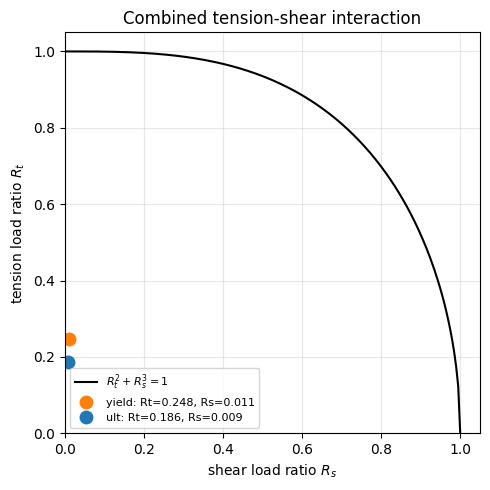

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
Rs_c = np.linspace(0, 1, 200)
ax.plot(Rs_c, np.sqrt(np.clip(1 - Rs_c**3, 0, None)), "k-", label="$R_t^2+R_s^3=1$")

for basis, colour in (("yield", "tab:orange"), ("ult", "tab:blue")):
    Rt, Rs = M.load_ratios(analysis.P_b, load_case.V, fastener, bolt_mat,
                           basis, load_case.SF_shear, SHEAR_PLANE_IN_SHANK)
    ax.plot(Rs, Rt, "o", color=colour, ms=9, label=f"{basis}: Rt={Rt:.3f}, Rs={Rs:.3f}")
    tm = M.combined_margin(Rt, Rs, basis, method="tm106943").MS
    gl = M.combined_margin(Rt, Rs, basis, method="guideline").MS
    print(f"{basis:>6}:  MS(TM-106943) = {tm:7.3f}    MOS(Guideline) = {gl:7.3f}")

ax.set_xlabel("shear load ratio $R_s$"); ax.set_ylabel("tension load ratio $R_t$")
ax.set_xlim(0, 1.05); ax.set_ylim(0, 1.05); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title("Combined tension-shear interaction")
plt.tight_layout(); plt.show()

## 6. Sensitivity

How much external load the joint tolerates before the governing margin goes
negative. Far more useful than a single-point answer when sizing.


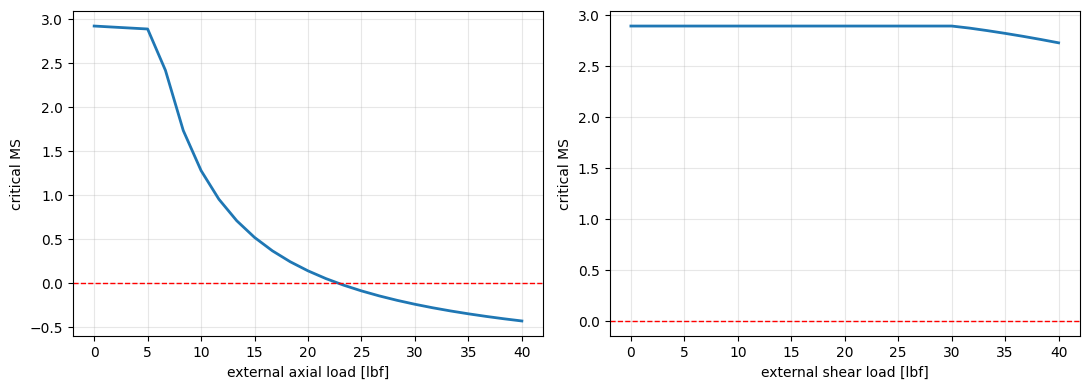

largest swept axial load with a positive margin: 21.7 lbf


In [8]:
def sweep(values, attr):
    rows = []
    for v in values:
        lc = LoadCase(**{**load_case.__dict__, attr: v})
        a = JointAnalysis(fastener, bolt_mat, joint, preload, lc,
                          insert=insert, abutment=abutment,
                          shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)
        rows.append({attr: v, "critical MS": a.critical.MS, "mode": a.critical.mode})
    return pd.DataFrame(rows)

axial = sweep(np.linspace(0, max(4 * P_ET, 40), 25), "P_et")
shear = sweep(np.linspace(0, max(4 * V_SHEAR, 40), 25), "V")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, d, col, lbl in ((axes[0], axial, "P_et", "external axial load [lbf]"),
                        (axes[1], shear, "V", "external shear load [lbf]")):
    ax.plot(d[col], d["critical MS"], lw=2)
    ax.axhline(0, color="r", ls="--", lw=1)
    ax.set_xlabel(lbl); ax.set_ylabel("critical MS"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

ok = axial[axial["critical MS"] >= 0]["P_et"]
print(f"largest swept axial load with a positive margin: {ok.max():.1f} lbf"
      if len(ok) < len(axial) else
      "positive margin across the entire swept axial range")

## 7. Preload sensitivity

Bolt strength and separation pull in opposite directions: more preload protects
against separation and hurts bolt tension. This shows the usable window.


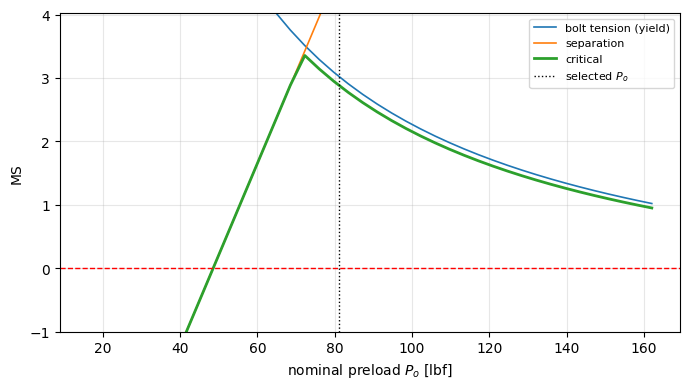

In [9]:
rows = []
for Po in np.linspace(0.2 * preload.Po, 2.0 * preload.Po, 40):
    p = Preload(Po=Po, u=preload.u, relax=preload.relax,
                K=preload.K, d_major=preload.d_major)
    a = JointAnalysis(fastener, bolt_mat, joint, p, load_case,
                      insert=insert, abutment=abutment,
                      shear_plane_in_shank=SHEAR_PLANE_IN_SHANK)
    byname = {(r.mode, r.basis): r.MS for r in a.results}
    rows.append({"Po": Po,
                 "bolt tension (yield)": byname[("bolt tension", "yield")],
                 "separation": byname[("joint separation", "n/a")],
                 "critical": a.critical.MS})
sens = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for c in ("bolt tension (yield)", "separation", "critical"):
    ax.plot(sens["Po"], sens[c], label=c, lw=2 if c == "critical" else 1.2)
ax.axhline(0, color="r", ls="--", lw=1)
ax.axvline(preload.Po, color="k", ls=":", lw=1, label="selected $P_o$")
ax.set_xlabel("nominal preload $P_o$ [lbf]"); ax.set_ylabel("MS")
ax.set_ylim(-1, min(10, sens["critical"].max() * 1.2)); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Assembly summary

In [10]:
summary = {
    "Fastener": f"{THREAD} {HEAD_STYLE}, {bolt_mat.name}",
    "Quantity": NUMBER_OF_BOLTS,
    "Nominal torque [lbf-in]": round(preload.torque_nominal, 3),
    "Torque range [lbf-in]": f"{t_lo:.3f} - {t_hi:.3f}",
    "Nominal preload [lbf]": round(preload.Po, 1),
    "Total clamp force [lbf]": round(preload.Po * NUMBER_OF_BOLTS, 1),
    "Bolt axial load P_b [lbf]": round(analysis.P_b, 2),
    "Thermal load [lbf]": round(analysis.P_thermal, 2),
    "Governing mode": f"{analysis.critical.mode} ({analysis.critical.basis})",
    "Governing MS": round(analysis.critical.MS, 3),
    "Verdict": "PASS" if analysis.passes else "FAIL",
}
pd.Series(summary).to_frame("value")

,value
Fastener,"2-56 socket, A286 fastener (AMS 5731/5737, 160..."
Quantity,7
Nominal torque [lbf-in],1.3930
Torque range [lbf-in],0.906 - 1.881
Nominal preload [lbf],81.0000
Total clamp force [lbf],567.0000
Bolt axial load P_b [lbf],110.1100
Thermal load [lbf],-24.9900
Governing mode,head/washer bearing (yield)
Governing MS,2.8890


## 9. Verification

Run the regression suite before trusting any result. Each `revb` test pins one
of the defects listed in the table at the top.


In [11]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "../tests", "-q"],
                     capture_output=True, text=True).stdout[-1200:])


==================================== ERRORS ====================================
___________________ ERROR collecting tests/test_boltjoint.py ___________________
ImportError while importing test module '/home/claude/work/boltjoint_proj/tests/test_boltjoint.py'.
Hint: make sure your test modules/packages have valid Python names.
Traceback:
/usr/lib/python3.12/importlib/__init__.py:90: in import_module
    return _bootstrap._gcd_import(name[level:], package, level)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
../tests/test_boltjoint.py:7: in <module>
    from boltjoint import (
E   ModuleNotFoundError: No module named 'boltjoint'
=========================== short test summary info ============================
ERROR ../tests/test_boltjoint.py
!!!!!!!!!!!!!!!!!!!! Interrupted: 1 error during collection !!!!!!!!!!!!!!!!!!!!
1 error in 0.22s



## 10. Limitations

- The combined-load margins (TM-106943 eqs. 59/62) can be **unconservative** for
  shear-critical joints. TM-106943 explicitly cautions that its equations assume
  shear is small relative to the axial load. Check the interaction curve directly
  when margins are below ~0.5, and use Bruhn / NASA TM X-73305 for tear-out and
  bearing when `e/D < 1.5` or margins are marginal.
- Material properties in `boltjoint/materials.py` are **typical values for
  convenience only**. Replace them with MMPDS / the applicable material and
  fastener procurement specification before releasing any analysis.
- Bearing allowables default to `1.5*Ftu` / `1.5*Fty`, a placeholder. Use real
  bearing data.
- Thermal treatment assumes a uniform temperature change and a
  thickness-weighted joint CTE. For dissimilar stacks with large CTE spread, use
  the layer-by-layer method of the Guideline sec. 7.
- Fatigue, self-loosening, creep of dielectrics, and gapping under bending are
  not covered.
- Single-fastener analysis. Load distribution across a pattern must be done
  upstream.
